In [1]:
from pathlib import Path
import yaml

import pandas as pd
import random
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

In [2]:
DATA_DIR = Path('../data/raw')
IMAGE_EXTS = {'.jpg', '.jpeg', '.png'}

print("Data folder found:", DATA_DIR.exists())

Data folder found: True


In [3]:
for split in ["train", "valid", "test"]:
    images = [p for p in (DATA_DIR / split / "images").iterdir() if p.suffix.lower() in IMAGE_EXTS]
    labels = list((DATA_DIR / split / "labels").glob("*.txt"))
    print(f"{split:6} images: {len(images):5}  labels: {len(labels):5}")

CONFIG_PATH = Path("../data/raw/data.yaml")

with open(CONFIG_PATH) as f:
    data_cfg = yaml.safe_load(f)

print()
print(data_cfg)

train  images:  2143  labels:  2143
valid  images:   612  labels:   612
test   images:   308  labels:   308

{'train': '../train/images', 'val': '../valid/images', 'test': '../test/images', 'nc': 3, 'names': ['glioma', 'meningioma', 'pituitary']}


In [4]:
class_names = data_cfg["names"]
rows = []
empty_files = {}

for split in ["train", "valid", "test"]:
    empty_files[split] = 0
    for label_file in (DATA_DIR / split / "labels").glob("*.txt"):
        lines = label_file.read_text().strip().splitlines()
        if not lines:
            empty_files[split] += 1
        for line in lines:
            parts = line.split()
            rows.append({
                "split": split,
                "file": label_file.stem,
                "class_id": int(parts[0]),
                "n_values": len(parts),
            })

df = pd.DataFrame(rows)
df["class_name"] = df["class_id"].map(lambda i: class_names[i])

print("Total boxes:", len(df))
print("Values per label line:", df["n_values"].unique())
print("Empty label files:", empty_files)

Total boxes: 3063
Values per label line: [17 41 25 51 23 43 15 27 39 29 47 21 35 19 31 37 65 33 45 11 13 83 49 55
 59 61 69 71 63 53 75 93 57 67 81 73 85]
Empty label files: {'train': 0, 'valid': 0, 'test': 0}


class_name  glioma  meningioma  pituitary
split                                    
train          983         502        658
valid          285         142        185
test           159          62         87


<Axes: title={'center': 'Boxes per class'}, xlabel='class_name'>

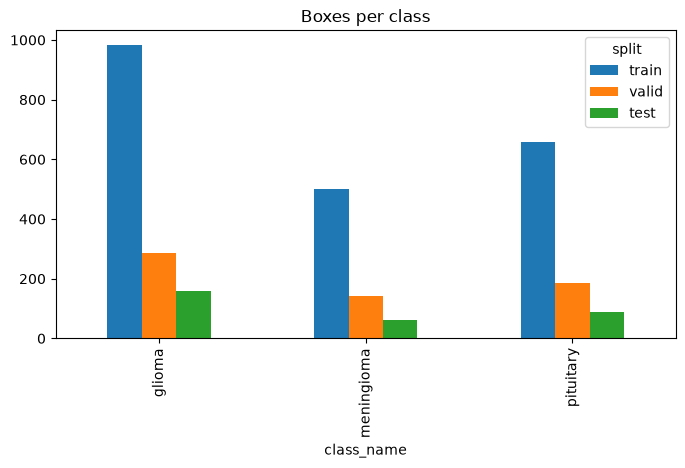

In [5]:
counts = df.groupby(["split", "class_name"]).size().unstack(fill_value=0)
counts = counts.loc[["train", "valid", "test"]]
print(counts)

counts.T.plot(
    kind="bar", 
    figsize=(8, 4), 
    title="Boxes per class"
)

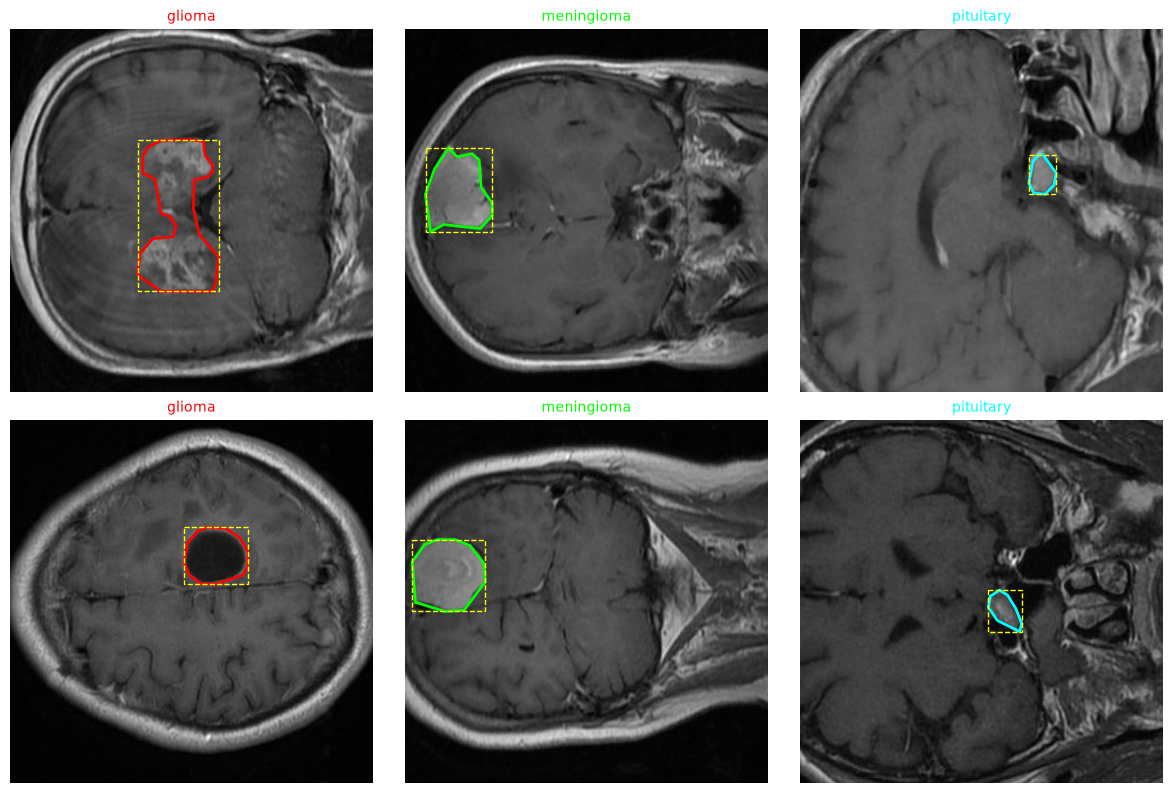

In [6]:
COLORS = {0: "red", 1: "lime", 2: "cyan"}

def show_samples(split="train", per_class=2, seed=42):
    random.seed(seed)
    lab_dir = DATA_DIR / split / "labels"
    by_class = {0: [], 1: [], 2: []}
    for lf in lab_dir.glob("*.txt"):
        by_class[int(lf.read_text().split()[0])].append(lf)

    chosen = []
    for cls_id in by_class:
        chosen += random.sample(by_class[cls_id], per_class)

    fig, axes = plt.subplots(2, 3, figsize=(12, 8))
    for ax, lf in zip(axes.T.ravel(), chosen):
        img_path = next(p for p in (DATA_DIR / split / "images").glob(lf.stem + ".*")
                        if p.suffix.lower() in IMAGE_EXTS)
        img = Image.open(img_path)
        w, h = img.size
        ax.imshow(img, cmap="gray")

        parts = lf.read_text().split()
        cls = int(parts[0])
        coords = list(map(float, parts[1:]))
        xs = [x * w for x in coords[0::2]]
        ys = [y * h for y in coords[1::2]]

        ax.add_patch(patches.Polygon(list(zip(xs, ys)), fill=False,
                                     edgecolor=COLORS[cls], linewidth=2))
        ax.add_patch(patches.Rectangle((min(xs), min(ys)), max(xs) - min(xs), max(ys) - min(ys),
                                       fill=False, edgecolor="yellow", linestyle="--", linewidth=1))
        ax.set_title(class_names[cls], fontsize=10, color=COLORS[cls])
        ax.axis("off")

    plt.tight_layout()
    plt.show()

show_samples("train")

class_name       glioma  meningioma  pituitary
width_px  count  1427.0       706.0      930.0
          mean    152.1       131.0       92.8
          std      67.1        51.2       40.2
          min      30.3        28.5       28.5
          25%     101.6        96.3       62.4
          50%     144.4       124.8       85.6
          75%     190.8       163.6      114.1
          max     520.6       356.5      287.0
height_px count  1427.0       706.0      930.0
          mean    151.0       133.4       94.8
          std      68.5        48.1       32.1
          min      30.3        37.4       35.7
          25%     102.5        98.1       71.3
          50%     142.6       128.4       90.9
          75%     189.0       164.0      112.3
          max     533.0       279.9      289.6
area_pct  count  1427.0       706.0      930.0
          mean      6.4         4.7        2.4
          std       5.1         3.2        1.8
          min       0.3         0.4        0.3
          25%

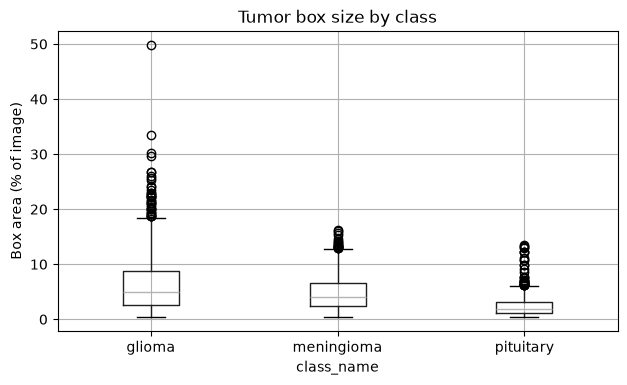

In [7]:
box_rows = []
for split in ["train", "valid", "test"]:
    for lf in (DATA_DIR / split / "labels").glob("*.txt"):
        parts = lf.read_text().split()
        cls = int(parts[0])
        coords = list(map(float, parts[1:]))
        xs, ys = coords[0::2], coords[1::2]
        bw, bh = max(xs) - min(xs), max(ys) - min(ys)
        box_rows.append({
            "split": split,
            "class_name": class_names[cls],
            "width_px": bw * 640,
            "height_px": bh * 640,
            "area_pct": bw * bh * 100,
        })

box_df = pd.DataFrame(box_rows)
print(box_df.groupby("class_name")[["width_px", "height_px", "area_pct"]].describe().round(1).T)

box_df.boxplot(column="area_pct", by="class_name", figsize=(7, 4))
plt.ylabel("Box area (% of image)")
plt.suptitle("")
plt.title("Tumor box size by class")
plt.show()

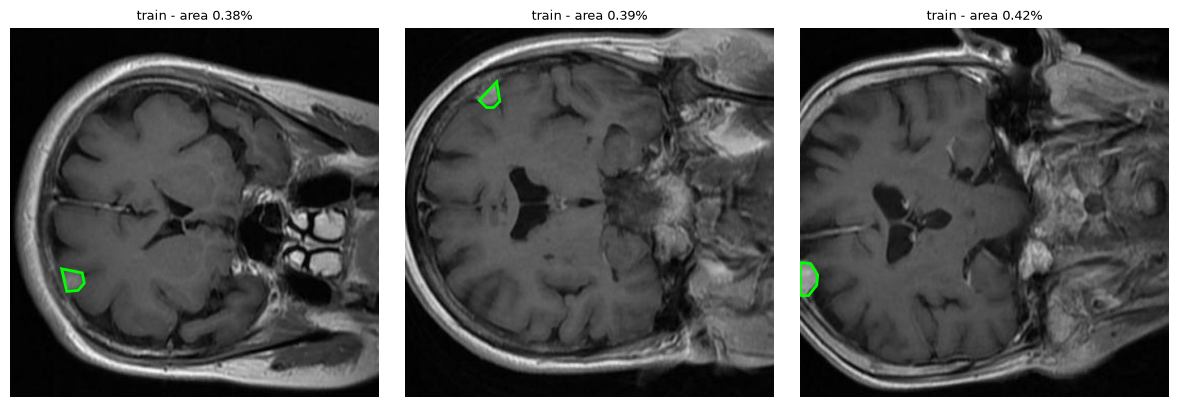

In [8]:
tiny = []
for split in ["train", "valid", "test"]:
    for lf in (DATA_DIR / split / "labels").glob("*.txt"):
        parts = lf.read_text().split()
        if int(parts[0]) != 1:
            continue
        coords = list(map(float, parts[1:]))
        xs, ys = coords[0::2], coords[1::2]
        area = (max(xs) - min(xs)) * (max(ys) - min(ys)) * 100
        tiny.append((area, split, lf))

tiny.sort(key=lambda t: t[0])

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, (area, split, lf) in zip(axes, tiny[:3]):
    img_path = next(p for p in (DATA_DIR / split / "images").glob(lf.stem + ".*")
                    if p.suffix.lower() in IMAGE_EXTS)
    img = Image.open(img_path)
    w, h = img.size
    ax.imshow(img, cmap="gray")
    coords = list(map(float, lf.read_text().split()[1:]))
    pts = list(zip([x * w for x in coords[0::2]], [y * h for y in coords[1::2]]))
    ax.add_patch(patches.Polygon(pts, fill=False, edgecolor="lime", linewidth=2))
    ax.set_title(f"{split} - area {area:.2f}%", fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [9]:
import shutil

bad_stem = tiny[0][2].stem
print("Moving:", bad_stem)

excluded = DATA_DIR.parent / "excluded"
(excluded / "images").mkdir(parents=True, exist_ok=True)
(excluded / "labels").mkdir(parents=True, exist_ok=True)

for img in (DATA_DIR / "train" / "images").glob(bad_stem + ".*"):
    shutil.move(str(img), excluded / "images" / img.name)

shutil.move(str(DATA_DIR / "train" / "labels" / f"{bad_stem}.txt"),
            excluded / "labels" / f"{bad_stem}.txt")

print("train images:", len(list((DATA_DIR / "train" / "images").iterdir())))
print("train labels:", len(list((DATA_DIR / "train" / "labels").glob("*.txt"))))

Moving: 394_jpg.rf.e37a4ee9b3363d18c5d3de1dd14fe35c
train images: 2142
train labels: 2142


In [10]:
restore = "394_jpg.rf.e37a4ee9b3363d18c5d3de1dd14fe35c"
excluded = DATA_DIR.parent / "excluded"

shutil.move(str(excluded / "labels" / f"{restore}.txt"),
            DATA_DIR / "train" / "labels" / f"{restore}.txt")
for img in (excluded / "images").glob(restore + ".*"):
    shutil.move(str(img), DATA_DIR / "train" / "images" / img.name)

print("train images:", len(list((DATA_DIR / "train" / "images").iterdir())))
print("train labels:", len(list((DATA_DIR / "train" / "labels").glob("*.txt"))))

train images: 2143
train labels: 2143


In [11]:
bad_stem = "518_jpg.rf.6423bbde42b291c9924e0bd70328203f"
excluded = DATA_DIR.parent / "excluded"
(excluded / "images").mkdir(parents=True, exist_ok=True)
(excluded / "labels").mkdir(parents=True, exist_ok=True)

label_file = DATA_DIR / "train" / "labels" / f"{bad_stem}.txt"
if label_file.exists():
    shutil.move(str(label_file), excluded / "labels" / label_file.name)
    for img in (DATA_DIR / "train" / "images").glob(bad_stem + ".*"):
        shutil.move(str(img), excluded / "images" / img.name)
    print("Moved", bad_stem)
else:
    print("Already moved, nothing to do")

Already moved, nothing to do
